# Wheel movement states across learning

The proficient wheel model (`segmentation/wheel_movement_clusters.py`: whole-movement split CW / balanced / CCW,
GMM 7 / 6 / 7 = 20 clusters, merged into the paper's 8 states) applied unchanged to every IBL `wheelMoves` movement of
the learning timepoints: **Early** (first training session), **Late** (last training session), **Pre-rec** (up to 3
biased sessions before recording) and **Proficient** (the LDA cohort). QC 'filtered out' sessions dropped.

Training / biased wheel comes from the 200 Hz wheel-only design matrices, averaged into 1/60 s bins to match the 60 Hz
proficient input (`learning_individuality/wheel/wheel_states_stages.py`). Also shown: the no-split, no-merge K = 6 states.
Nothing is saved.

Caveat: the model was fitted on proficient movements; early-training movements that look like nothing in the proficient
repertoire are still forced into the nearest proficient cluster.

In [1]:
import sys, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
HERE = pathlib.Path.cwd().resolve()
PI = next(p for p in [HERE, *HERE.parents] if (p / 'paper_style.py').exists())
for p in (PI, PI / 'segmentation', PI / 'learning_individuality' / 'wheel'):
    sys.path.insert(0, str(p))
import paper_style as ps
import wheel_movement_clusters as wmc
import wheel_states_stages as wss
ps.use('paper', dpi=110)

TP = list(wss.TIMEPOINTS)
TP_COL = dict(zip(TP, ['#9ecae1', '#4292c6', '#2171b5', '#08306b']))
EPOCHS = ['pre-stim', 'response', 'post-feedback']
PAPER = wmc.load_model('proficient', 21)
N8 = [n.replace('left', 'CW').replace('right', 'CCW').replace('both', 'Bal') for n in wmc.state_names(PAPER, 'small_side_vigor')]
C8 = wmc.colours(PAPER, 'small_side_vigor')
C20 = wmc.colours(PAPER)[1:]
U6 = wss.nosplit_model()
CU6 = ps.state_palette(np.log(U6['desc'].peak_rad_s.values), hues=wmc.WHEEL_HUES)

M = wss.label_all()
M['timepoint'] = pd.Categorical(M.timepoint, TP, ordered=True)
cov = M.groupby('timepoint', observed=True).agg(sessions=('eid', 'nunique'), mice=('mouse', 'nunique'), movements=('eid', 'size'))
expected = wss.sessions().groupby('timepoint').size().reindex(TP)
cov['of_expected'] = expected.values
cov

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


,sessions,mice,movements,of_expected
timepoint,,,,
Early,43,43,31423,43
Late,49,49,85364,49
Pre-rec,98,38,175325,98
Proficient,269,58,391651,269


## How much the wheel moves

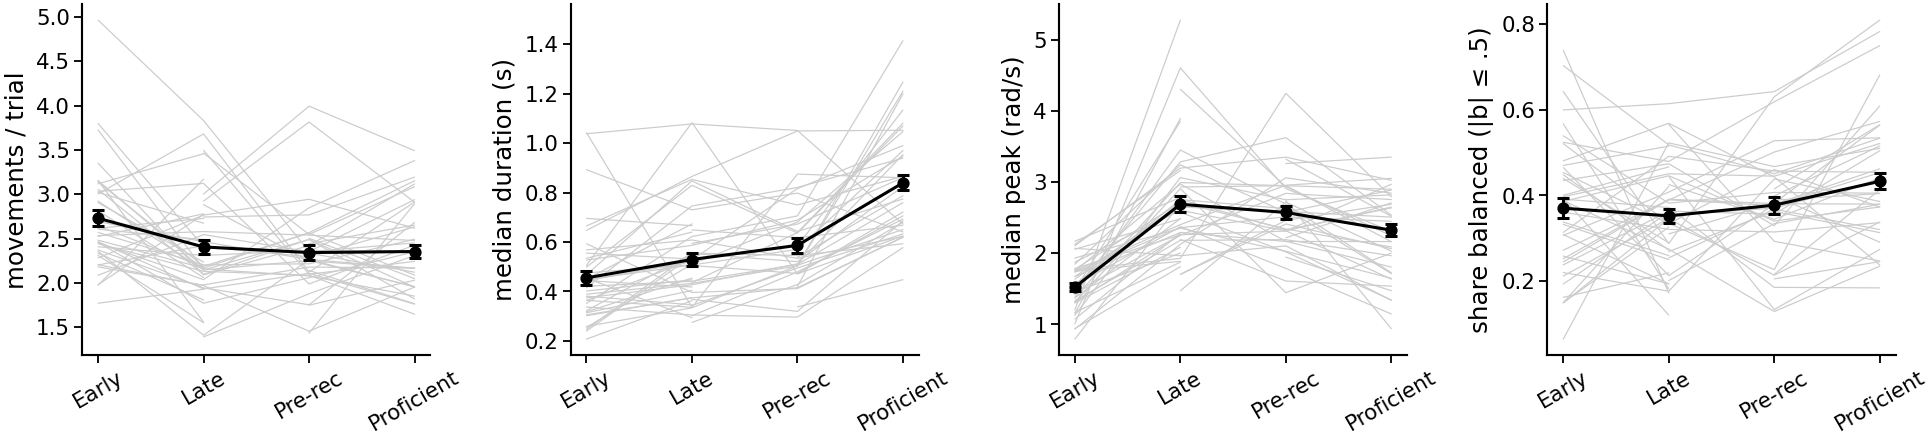

,moves_per_trial,dur,peak,balanced
timepoint,,,,
Early,2.569,0.415,1.495,0.387
Late,2.203,0.507,2.574,0.346
Pre-rec,2.279,0.536,2.543,0.380
Proficient,2.243,0.767,2.318,0.409


In [2]:
S = (M.groupby(['timepoint', 'mouse', 'eid'], observed=True)
       .agg(n=('onset', 'size'), n_trials=('n_trials', 'first'), dur=('duration', 'median'), peak=('peak', 'median'),
            balanced=('balance', lambda b: np.mean(np.abs(b) <= .5)))
       .reset_index())
S['moves_per_trial'] = S.n / S.n_trials
MS = S.groupby(['timepoint', 'mouse'], observed=True)[['moves_per_trial', 'dur', 'peak', 'balanced']].mean().reset_index()
fig, axs = plt.subplots(1, 4, figsize=(9, 2.2))
for ax, (col, lab) in zip(axs, [('moves_per_trial', 'movements / trial'), ('dur', 'median duration (s)'),
                                ('peak', 'median peak (rad/s)'), ('balanced', 'share balanced (|b| ≤ .5)')]):
    for m, g in MS.groupby('mouse'):
        g = g.set_index('timepoint').reindex(TP)
        ax.plot(range(4), g[col], color='0.8', lw=0.4, zorder=0)
    q = MS.groupby('timepoint', observed=True)[col]
    ax.errorbar(range(4), q.mean(), q.sem(), color='k', marker='o', ms=3, lw=1, capsize=2)
    ax.set(xticks=range(4), ylabel=lab); ax.set_xticklabels(TP, rotation=30)
plt.tight_layout(); plt.show()
MS.groupby('timepoint', observed=True)[['moves_per_trial', 'dur', 'peak', 'balanced']].median().round(3)

## The paper's 8 states across timepoints
Share of each session's movements in each state (still = no movement, not counted), averaged per mouse, then over mice.

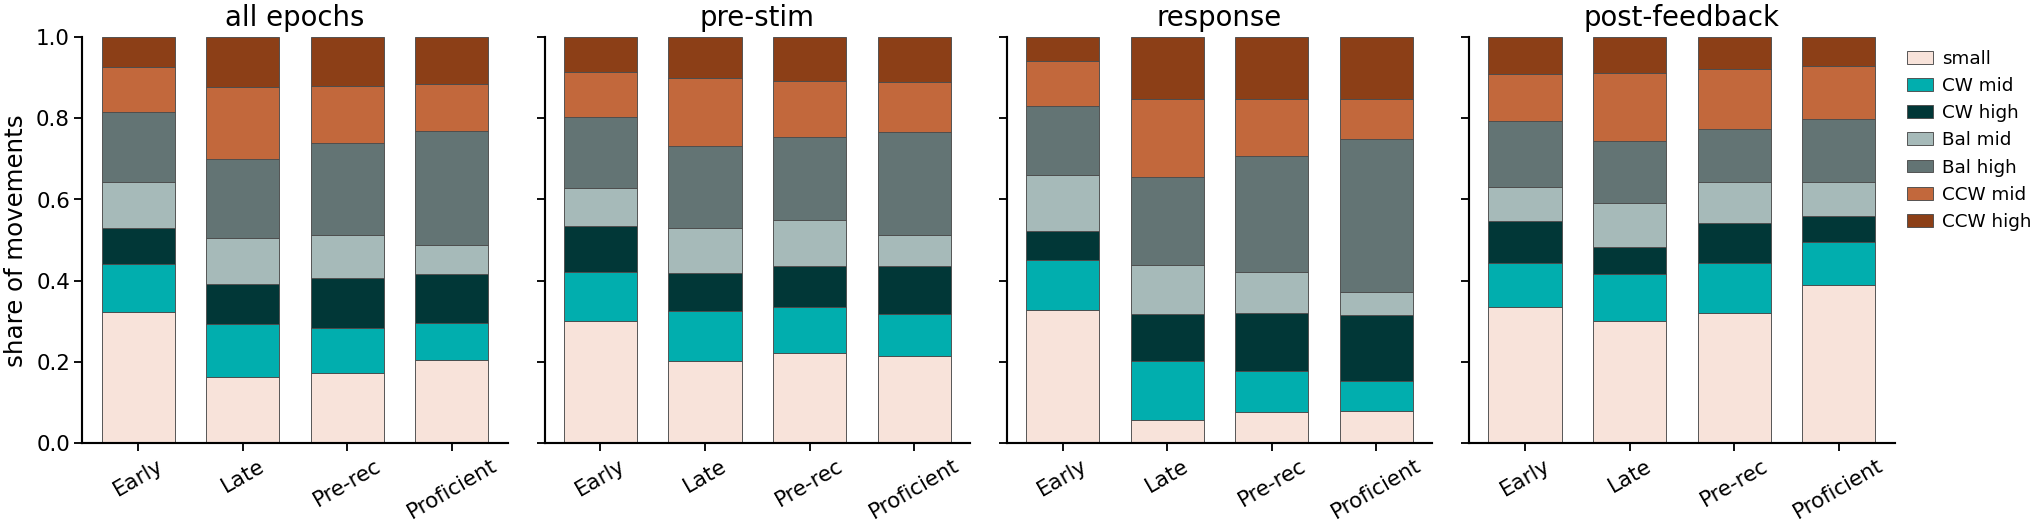

,small,CW mid,CW high,Bal mid,Bal high,CCW mid,CCW high
timepoint,,,,,,,
Early,0.323,0.117,0.088,0.114,0.171,0.111,0.075
Late,0.164,0.130,0.096,0.115,0.193,0.177,0.125
Pre-rec,0.172,0.112,0.122,0.105,0.227,0.141,0.122
Proficient,0.204,0.091,0.120,0.072,0.282,0.114,0.117


In [3]:
def shares(col, n_states, by=('timepoint', 'mouse', 'eid'), sub=None):
    d = M if sub is None else M[sub]
    ct = pd.crosstab([d[c] for c in by], d[col], normalize='index').reindex(columns=range(n_states), fill_value=0)
    return ct.groupby(level=['timepoint', 'mouse'], observed=True).mean()     # mouse means

M['s8i'] = M.s8 - 1                                       # 0..6 = small, CW mid, CW high, Bal mid, Bal high, CCW mid, CCW high
SH8 = shares('s8i', 7)
def stacked(ax, SH, names, cols, title):
    mean = SH.groupby(level='timepoint', observed=True).mean().reindex(TP)
    bottom = np.zeros(len(TP))
    for j in range(SH.shape[1]):
        ax.bar(range(len(TP)), mean[j], bottom=bottom, color=cols[j], ec='0.3', lw=0.3, label=names[j], width=0.7)
        bottom += mean[j].values
    ax.set(xticks=range(len(TP)), ylim=(0, 1), title=title); ax.set_xticklabels(TP, rotation=30)
fig, axs = plt.subplots(1, 4, figsize=(9.5, 2.6), sharey=True)
stacked(axs[0], SH8, N8[1:], C8[1:], 'all epochs')
for ax, ep in zip(axs[1:], EPOCHS):
    stacked(ax, shares('s8i', 7, sub=M.epoch == ep), N8[1:], C8[1:], ep)
axs[0].set_ylabel('share of movements'); axs[-1].legend(fontsize=6, frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout(); plt.show()
SH8.groupby(level='timepoint', observed=True).mean().reindex(TP).set_axis(N8[1:], axis=1).round(3)

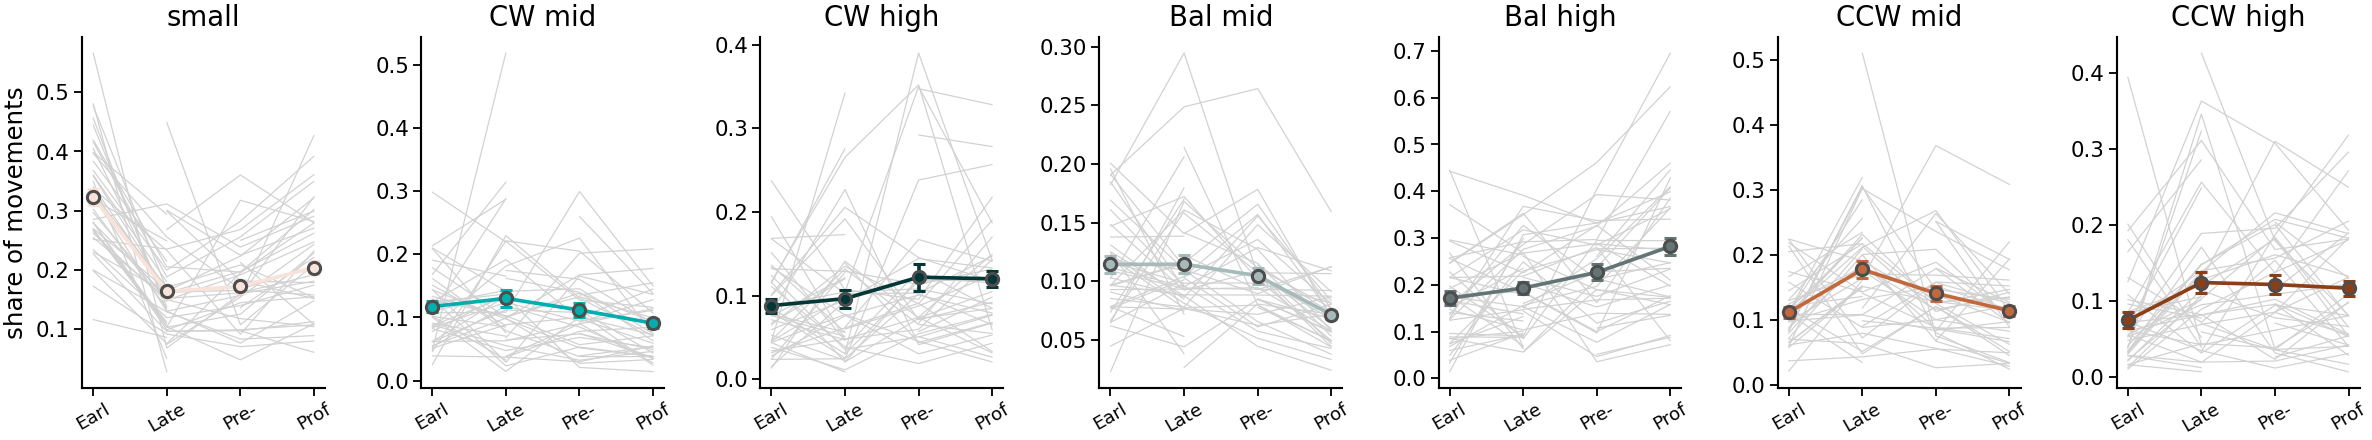

,state,pair,n_mice,mean_a,mean_b,p,q
0,small,Early → Late,40,0.322,0.153,0.000,0.000
1,small,Late → Pre-rec,32,0.171,0.172,0.536,0.750
2,small,Pre-rec → Proficient,38,0.172,0.218,0.000,0.001
3,CW mid,Early → Late,40,0.114,0.133,0.666,0.803
4,CW mid,Late → Pre-rec,32,0.105,0.111,0.905,0.905
5,CW mid,Pre-rec → Proficient,38,0.112,0.082,0.002,0.005
6,CW high,Early → Late,40,0.085,0.101,0.428,0.733
7,CW high,Late → Pre-rec,32,0.089,0.117,0.210,0.441
8,CW high,Pre-rec → Proficient,38,0.122,0.116,0.688,0.803
9,Bal mid,Early → Late,40,0.114,0.115,0.826,0.868


In [4]:
# per state, mice as lines; Wilcoxon between consecutive timepoints on the mice present in both (FDR over all tests)
fig, axs = plt.subplots(1, 7, figsize=(11, 2.2), sharey=False)
rows = []
for j, ax in enumerate(axs):
    W = SH8[j].unstack('timepoint').reindex(columns=TP)
    for _, r in W.iterrows():
        ax.plot(range(4), r.values, color='0.82', lw=0.4, zorder=0)
    ax.errorbar(range(4), W.mean(), W.sem(), color=C8[j + 1], mec='0.3', marker='o', ms=4, lw=1.2, capsize=2)
    ax.set(xticks=range(4), title=N8[j + 1]); ax.set_xticklabels([t[:4] for t in TP], rotation=30, fontsize=6)
    for a, b in zip(TP[:-1], TP[1:]):
        p_ = W[[a, b]].dropna()
        rows.append(dict(state=N8[j + 1], pair=f'{a} → {b}', n_mice=len(p_), mean_a=p_[a].mean(), mean_b=p_[b].mean(),
                         p=wilcoxon(p_[a], p_[b]).pvalue if len(p_) > 5 else np.nan))
axs[0].set_ylabel('share of movements')
plt.tight_layout(); plt.show()
T8 = pd.DataFrame(rows); T8['q'] = multipletests(T8.p.fillna(1), method='fdr_bh')[1]
T8.round(3)

## The 20 clusters (before merging) across timepoints

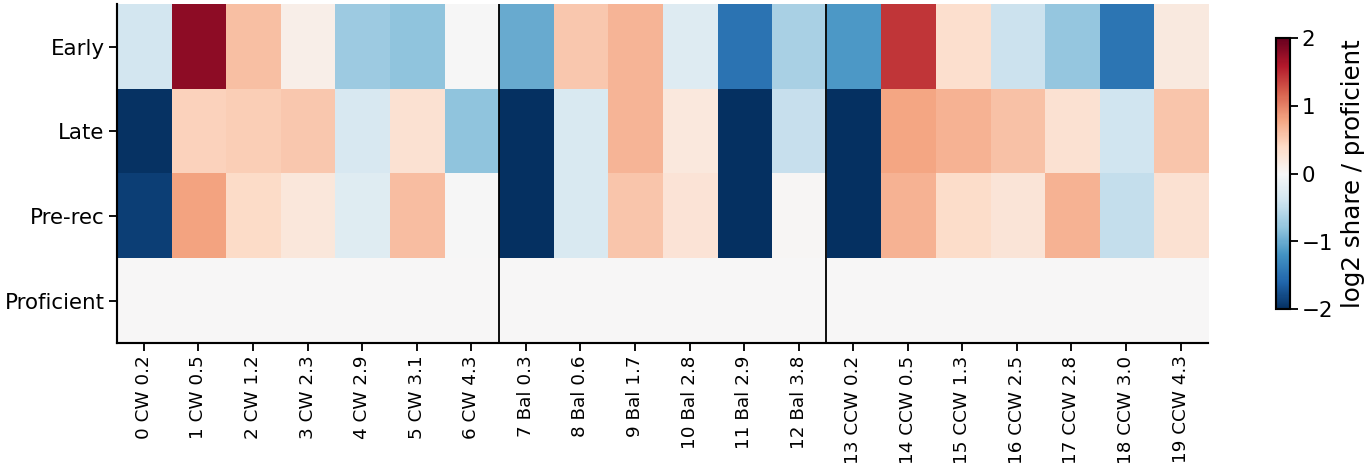

c20,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
timepoint,,,,,,,,,,,,,,,,,,,,
Early,0.020,0.107,0.066,0.051,0.035,0.012,0.041,0.016,0.068,0.114,0.079,0.035,0.057,0.015,0.097,0.065,0.046,0.013,0.022,0.040
Late,0.007,0.042,0.062,0.069,0.046,0.027,0.024,0.006,0.038,0.115,0.110,0.019,0.064,0.008,0.062,0.084,0.093,0.027,0.045,0.052
Pre-rec,0.007,0.054,0.057,0.055,0.048,0.033,0.041,0.008,0.038,0.105,0.115,0.021,0.090,0.007,0.059,0.067,0.074,0.036,0.043,0.044
Proficient,0.026,0.031,0.044,0.047,0.058,0.021,0.041,0.032,0.047,0.072,0.095,0.098,0.089,0.033,0.036,0.052,0.062,0.022,0.060,0.035


In [5]:
SH20 = shares('c20', 20).groupby(level='timepoint', observed=True).mean().reindex(TP)
d = PAPER['desc']
fig, ax = plt.subplots(figsize=(8, 2.0))
im = ax.imshow(np.log2(SH20.values / SH20.loc['Proficient'].values), cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set(yticks=range(4), yticklabels=TP, xticks=range(20))
ax.set_xticklabels([f'{c} {"CW" if s == "left" else "CCW" if s == "right" else "Bal"} {p:.1f}' for c, s, p in
                    zip(d.index, d.side, d.peak_rad_s)], rotation=90, fontsize=6)
for b in (6.5, 12.5): ax.axvline(b, color='k', lw=0.6)
plt.colorbar(im, ax=ax, label='log2 share / proficient', shrink=0.8); plt.show()
SH20.round(3)

## The no-split, no-merge K = 6 states across timepoints

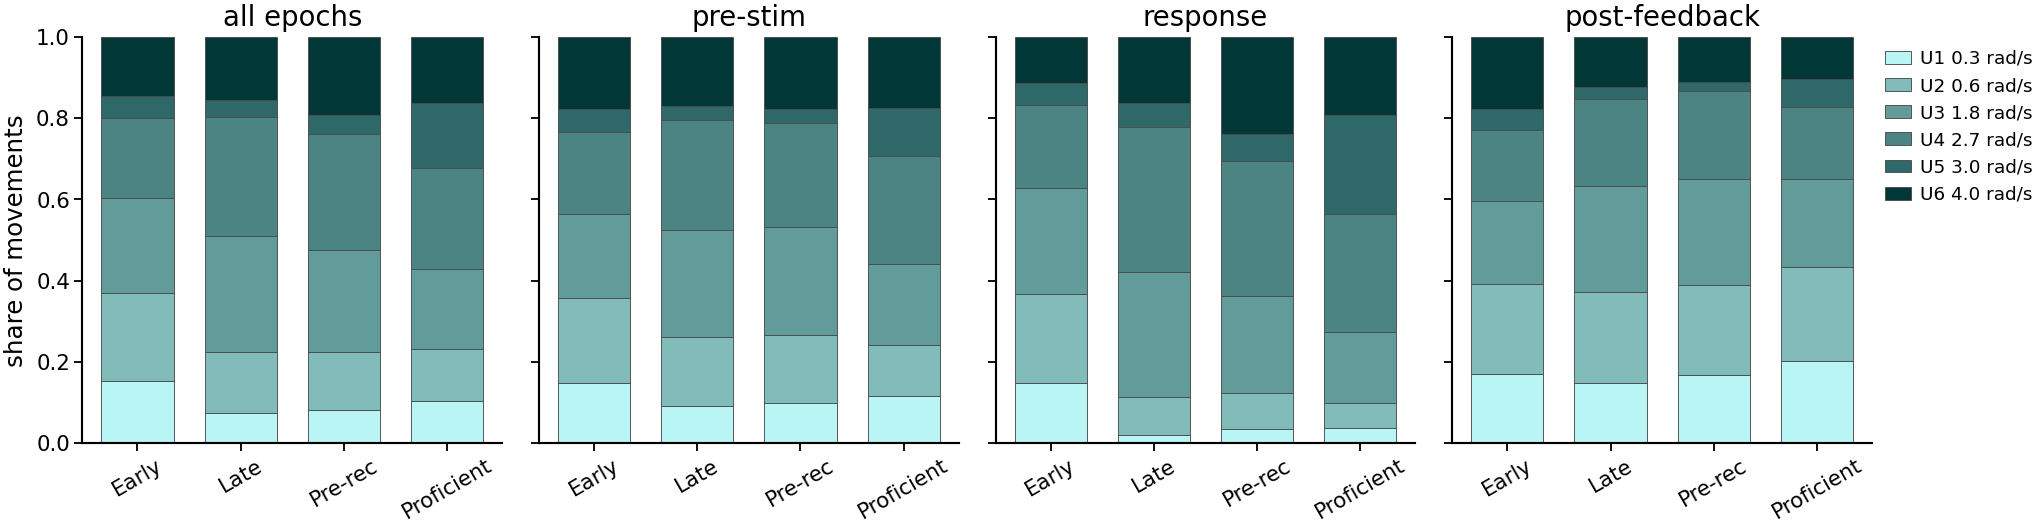

,U1 0.3 rad/s,U2 0.6 rad/s,U3 1.8 rad/s,U4 2.7 rad/s,U5 3.0 rad/s,U6 4.0 rad/s
timepoint,,,,,,
Early,0.153,0.217,0.233,0.198,0.055,0.144
Late,0.073,0.151,0.285,0.293,0.043,0.155
Pre-rec,0.082,0.143,0.252,0.284,0.047,0.193
Proficient,0.102,0.130,0.196,0.248,0.162,0.162


In [6]:
SHU = shares('u6', 6)
fig, axs = plt.subplots(1, 4, figsize=(9.5, 2.6), sharey=True)
UN = [f'U{c + 1} {p:.1f} rad/s' for c, p in enumerate(U6['desc'].peak_rad_s)]
stacked(axs[0], SHU, UN, CU6, 'all epochs')
for ax, ep in zip(axs[1:], EPOCHS):
    stacked(ax, shares('u6', 6, sub=M.epoch == ep), UN, CU6, ep)
axs[0].set_ylabel('share of movements'); axs[-1].legend(fontsize=6, frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout(); plt.show()
SHU.groupby(level='timepoint', observed=True).mean().reindex(TP).set_axis(UN, axis=1).round(3)

## Does the choice movement report the side? (direction rules across learning)
First response-epoch movement of each correct trial: does its direction match the reported side (+ = CCW = right
stimulus)? Whole-movement balance sign vs first-half sign; and how often the paper split calls it balanced.

In [7]:
# stimulus side per trial needs the trials tables
def stim_side(tp, mouse, eid):
    if tp == 'Proficient':
        tr = pd.read_parquet(wmc.moves_dir('proficient') + f'trials_{eid}_{mouse}')
    else:
        tr = pd.read_parquet(wss._dm_path(mouse, eid) / f'trials_{eid}_{mouse}')
    return pd.DataFrame({'eid': eid, 'trial': np.arange(len(tr)), 'right': tr.contrastRight.notna().values,
                         'correct': tr.feedbackType.values == 1})
SS = pd.concat([stim_side(*r) for r in M[['timepoint', 'mouse', 'eid']].drop_duplicates().astype(str).itertuples(index=False)])
ch = (M[(M.epoch == 'response') & (M.trial >= 0)].sort_values('onset').groupby(['eid', 'trial']).head(1)
      .merge(SS, on=['eid', 'trial']))
ch = ch[ch.correct]
want = np.where(ch.right, 1, -1)
ch['whole_ok'] = np.sign(ch.balance) == want
ch['half_ok'] = ch.dir_half == want
ch['called_balanced'] = np.abs(ch.balance) <= .5
(ch.groupby(['timepoint', 'mouse'], observed=True)[['whole_ok', 'half_ok', 'called_balanced']].mean()
   .groupby(level='timepoint', observed=True).mean().reindex(TP).round(3))

,whole_ok,half_ok,called_balanced
timepoint,,,
Early,0.809,0.818,0.388
Late,0.874,0.922,0.340
Pre-rec,0.815,0.888,0.408
Proficient,0.840,0.894,0.468


## Do mice keep their relations? Mouse × mouse similarity, each timepoint vs Proficient

The question is not *what* changes but whether mice that are similar to each other at one timepoint are still similar
at another (as `relational_structure.ipynb`, same measures and conventions). Per mouse and timepoint, a wheel feature vector:
the share of movements in each state **within each epoch** (session mean, then mouse mean). Features z-scored within a
timepoint; RDM = correlation distance between mice; Mantel = Spearman between the two RDMs' upper triangles, mice permuted
in one of them. Each timepoint is compared with Proficient on the mice present in both.
Noise ceiling: split-half reliability of each RDM (split by session where a mouse has ≥ 2, else by trials), Spearman–Brown
corrected; a cross-timepoint Mantel cannot exceed √(rel_A · rel_B).

Also, per feature: the across-mouse Spearman between the timepoint and Proficient (does a mouse keep its rank?).
Processing differences between timepoints (60 Hz design matrix vs 200 Hz binned) do not matter here: only the ordering of
mice within a timepoint enters.

In [8]:
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr

def zscore_columns(df, mu=None, sd=None, eps=1e-8):
    X = np.asarray(df, dtype=float)
    if mu is None:
        mu, sd = X.mean(0), X.std(0)
    return pd.DataFrame((X - mu) / (sd + eps), index=df.index, columns=df.columns), mu, sd

def rdm(df, metric='correlation'):
    return squareform(pdist(np.asarray(df, dtype=float), metric=metric))

def mantel_test(a, b, n_perm=10000, seed=42):
    n = a.shape[0]; idx = np.triu_indices(n, k=1)
    obs = spearmanr(a[idx], b[idx])[0]
    rng = np.random.default_rng(seed)
    null = np.array([spearmanr(a[np.ix_(p, p)][idx], b[idx])[0] for p in (rng.permutation(n) for _ in range(n_perm))])
    return obs, (np.sum(null >= obs) + 1) / (n_perm + 1)

def features(d, col, K):
    """(mouse x [epoch x state]) share of movements per state within each epoch; session mean then mouse mean"""
    c = d.groupby(['mouse', 'eid', 'epoch', col]).size().unstack(col, fill_value=0).reindex(columns=range(K), fill_value=0)
    c = c.div(c.sum(1), axis=0).unstack('epoch').reindex(columns=pd.MultiIndex.from_product([range(K), EPOCHS]))
    return c.groupby(level='mouse').mean()

def halves(d, col, K, n_rep=20, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_rep):
        pick = np.zeros(len(d), bool)
        for m, g in d.groupby('mouse').groups.items():
            sess = d.loc[g, 'eid'].unique()
            if len(sess) >= 2:
                pick[d.index.get_indexer(g)] = d.loc[g, 'eid'].isin(rng.permutation(sess)[:len(sess) // 2]).values
            else:
                tr = d.loc[g, 'trial'].unique(); a = set(rng.permutation(tr)[:len(tr) // 2])
                pick[d.index.get_indexer(g)] = d.loc[g, 'trial'].isin(a).values
        out.append((features(d[pick], col, K), features(d[~pick], col, K)))
    return out

def reliability(H, mice, mu, sd):
    rs = []
    for A, B in H:
        keep = [m for m in mice if m in A.index and m in B.index]
        Az = zscore_columns(A.loc[keep].fillna(0), mu, sd)[0]; Bz = zscore_columns(B.loc[keep].fillna(0), mu, sd)[0]
        Ra, Rb = rdm(Az), rdm(Bz); i = np.triu_indices(len(keep), 1)
        rs.append(spearmanr(Ra[i], Rb[i])[0])
    r = np.nanmean(rs)
    return 2 * r / (1 + r)

Md = M.reset_index(drop=True)
FEATSETS = {'8 states x epoch': ('s8i', 7), '20 clusters x epoch': ('c20', 20), 'no-split K=6 x epoch': ('u6', 6)}
REL = {}
rows, rank_rows = [], []
for fname, (col, K) in FEATSETS.items():
    F = {tp: features(Md[Md.timepoint == tp], col, K).fillna(0) for tp in TP}
    for tp in TP[:-1]:
        mice = sorted(set(F[tp].index) & set(F['Proficient'].index))
        Za, mu_a, sd_a = zscore_columns(F[tp].loc[mice]); Zb, mu_b, sd_b = zscore_columns(F['Proficient'].loc[mice])
        r, p = mantel_test(rdm(Za), rdm(Zb))
        rel_a = reliability(halves(Md[(Md.timepoint == tp) & Md.mouse.isin(mice)], col, K), mice, mu_a, sd_a)
        rel_b = reliability(halves(Md[(Md.timepoint == 'Proficient') & Md.mouse.isin(mice)], col, K), mice, mu_b, sd_b)
        rows.append(dict(features=fname, pair=f'{tp} vs Proficient', n_mice=len(mice), mantel_rho=r, p=p,
                         rel_tp=rel_a, rel_prof=rel_b, ceiling=np.sqrt(max(rel_a, 0) * max(rel_b, 0))))
        if fname == '8 states x epoch':
            for c in F[tp].columns:
                x, y = F[tp].loc[mice, c], F['Proficient'].loc[mice, c]
                rank_rows.append(dict(pair=tp, state=N8[1:][c[0]], epoch=c[1], rho=spearmanr(x, y)[0], p=spearmanr(x, y)[1]))
RS = pd.DataFrame(rows); RS['rho/ceiling'] = RS.mantel_rho / RS.ceiling
RS.round(3)

,features,pair,n_mice,mantel_rho,p,rel_tp,rel_prof,ceiling,rho/ceiling
0,8 states x epoch,Early vs Proficient,43,-0.017,0.667,0.826,0.794,0.810,-0.021
1,8 states x epoch,Late vs Proficient,49,0.098,0.004,0.957,0.789,0.869,0.113
2,8 states x epoch,Pre-rec vs Proficient,38,0.473,0.000,0.766,0.744,0.755,0.626
3,20 clusters x epoch,Early vs Proficient,43,0.017,0.280,0.857,0.778,0.816,0.021
4,20 clusters x epoch,Late vs Proficient,49,0.089,0.006,0.941,0.770,0.852,0.105
5,20 clusters x epoch,Pre-rec vs Proficient,38,0.514,0.000,0.774,0.735,0.754,0.681
6,no-split K=6 x epoch,Early vs Proficient,43,0.032,0.161,0.734,0.809,0.771,0.042
7,no-split K=6 x epoch,Late vs Proficient,49,0.146,0.001,0.939,0.820,0.877,0.166
8,no-split K=6 x epoch,Pre-rec vs Proficient,38,0.398,0.000,0.791,0.790,0.791,0.504


In [9]:
RK = pd.DataFrame(rank_rows); RK['q'] = multipletests(RK.p, method='fdr_bh')[1]
print('per feature: does a mouse keep its rank (Spearman across mice, timepoint vs Proficient)')
display(RK.pivot_table(index=['state'], columns=['pair', 'epoch'], values='rho').reindex(index=N8[1:], columns=TP[:-1], level=0).round(2))
print('features with q < .05:'); display(RK[RK.q < .05].sort_values(['pair', 'q']).round(3))
# simple measures too
SM = MS.set_index(['timepoint', 'mouse'])
srows = []
for col in ['moves_per_trial', 'dur', 'peak', 'balanced']:
    for tp in TP[:-1]:
        a = SM.loc[tp][col]; b = SM.loc['Proficient'][col]; mice = a.index.intersection(b.index)
        r, p = spearmanr(a[mice], b[mice]); srows.append(dict(measure=col, pair=tp, n=len(mice), rho=r, p=p))
pd.DataFrame(srows).pivot(index='measure', columns='pair', values='rho').reindex(columns=TP[:-1]).round(2)

per feature: does a mouse keep its rank (Spearman across mice, timepoint vs Proficient)


pair             Early                            Late                    \
epoch    post-feedback pre-stim response post-feedback pre-stim response   
state                                                                      
small            -0.01     0.26    -0.06          0.41     0.43     0.10   
CW mid           -0.10     0.17     0.21          0.05     0.44    -0.09   
CW high           0.08     0.10     0.08         -0.00     0.19     0.23   
Bal mid          -0.03    -0.09    -0.21          0.14     0.23    -0.05   
Bal high          0.10     0.19     0.13          0.27     0.49     0.11   
CCW mid           0.38     0.10    -0.27          0.25     0.42     0.11   
CCW high         -0.17    -0.03     0.06          0.21     0.35     0.27   

pair           Pre-rec                    
epoch    post-feedback pre-stim response  
state                                     
small             0.61     0.70     0.50  
CW mid            0.65     0.74     0.52  
CW high           0.73     0.54     0.48  
Bal mid           0.42     0.55     0.07  
Bal high          0.60     0.69     0.56  
CCW mid           0.79     0.58     0.36  
CCW high          0.73     0.75     0.43

features with q < .05:


,pair,state,epoch,rho,p,q
17,Early,CCW mid,post-feedback,0.376,0.013,0.033
33,Late,Bal high,pre-stim,0.492,0.000,0.002
24,Late,CW mid,pre-stim,0.441,0.002,0.005
21,Late,small,pre-stim,0.426,0.002,0.007
36,Late,CCW mid,pre-stim,0.425,0.002,0.007
23,Late,small,post-feedback,0.413,0.003,0.009
39,Late,CCW high,pre-stim,0.346,0.015,0.036
59,Pre-rec,CCW mid,post-feedback,0.794,0.000,0.000
60,Pre-rec,CCW high,pre-stim,0.755,0.000,0.000
45,Pre-rec,CW mid,pre-stim,0.739,0.000,0.000


pair,Early,Late,Pre-rec
measure,,,
balanced,0.18,0.20,0.59
dur,-0.01,0.02,0.44
moves_per_trial,0.32,0.47,0.44
peak,-0.09,0.34,0.62
